In [4]:
## 1) Loading the Taxis Dataset

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


In [7]:
df=sns.load_dataset("taxis")
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


In [8]:
#2) Handling Missing Values

## Check for missing values

df.isnull().sum() 

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [9]:
## Impute missing values

df["payment"] = df["payment"].fillna(df["payment"].mode()[0])
df["pickup_zone"] = df["pickup_zone"].fillna(df["pickup_zone"].mode()[0])
df["dropoff_zone"] = df["dropoff_zone"].fillna(df["dropoff_zone"].mode()[0])
df["pickup_borough"] = df["pickup_borough"].fillna(df["pickup_borough"].mode()[0])
df["dropoff_borough"] = df["dropoff_borough"].fillna(df["dropoff_borough"].mode()[0])
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


In [10]:
df.isnull().sum() 

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

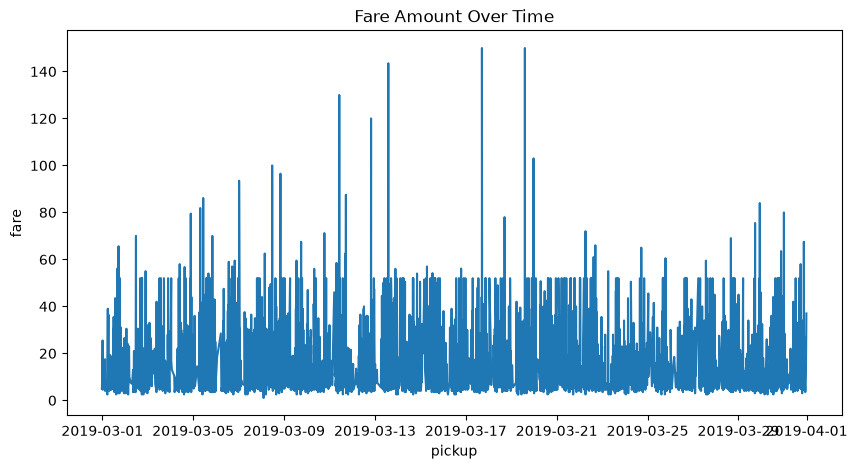

In [11]:
#3) Visualizations using Matplotlib/Pandas Plot:
## Line Chart

df["pickup"]=pd.to_datetime(df["pickup"])
df=df.sort_values(by="pickup")
plt.figure(figsize=(10,5))
plt.plot(df["pickup"],df["fare"])
plt.xlabel("pickup")
plt.ylabel("fare")
plt.title("Fare Amount Over Time")
plt.show()

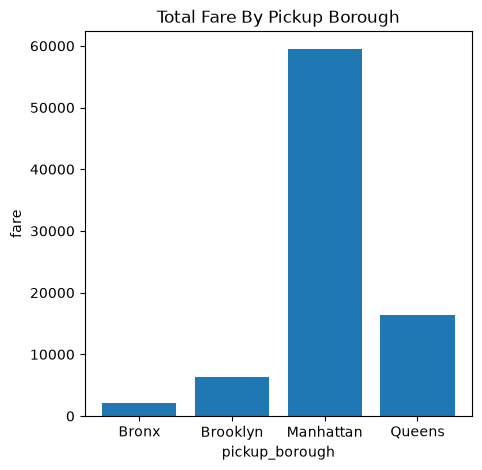

In [12]:
## Bar Chart
borough_fare=df.groupby("pickup_borough")["fare"].sum()

plt.figure(figsize=(5,5))
plt.bar(borough_fare.index,borough_fare.values)
plt.xlabel("pickup_borough")
plt.ylabel("fare")
plt.title("Total Fare By Pickup Borough")
plt.show()

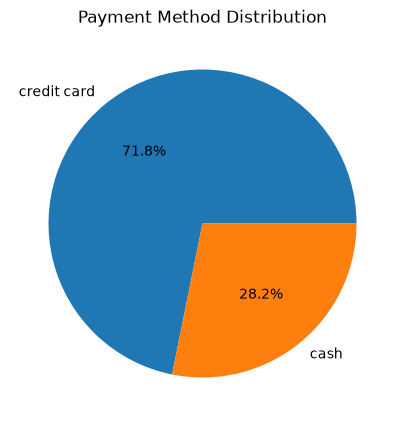

In [13]:
## Pei Chart
plt.figure(figsize=(6,5))
plt.pie(df["payment"].value_counts(),
labels=df["payment"].value_counts().index,
autopct="%1.1f%%"
)
plt.title("Payment Method Distribution")

plt.show()

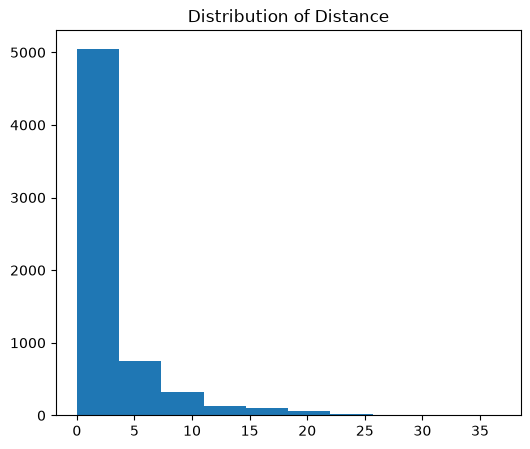

In [14]:
## Histogram

plt.figure(figsize=(6,5))
plt.hist(df["distance"])
plt.title("Distribution of Distance")

plt.show()

<Figure size 600x500 with 0 Axes>

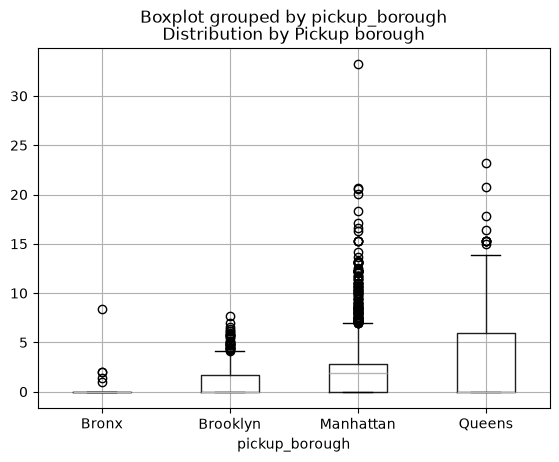

In [56]:
## Box Plot

plt.figure(figsize=(6,5))
df.boxplot(column="tip",by="pickup_borough")

plt.title("Distribution by Pickup borough")

plt.show()

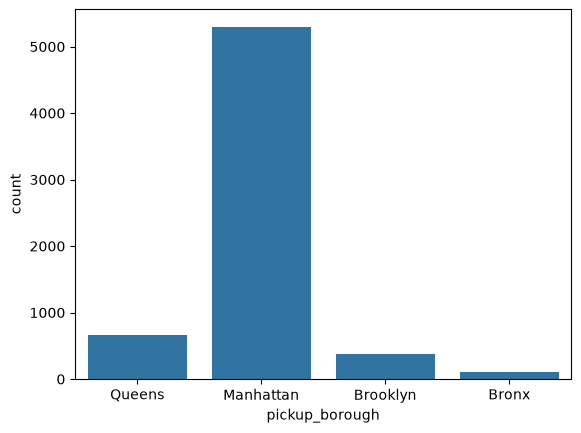

In [16]:
## Visualizations using Seaborn:

# Count Plot

sns.countplot(
    x="pickup_borough",
    data=df
)

plt.show()

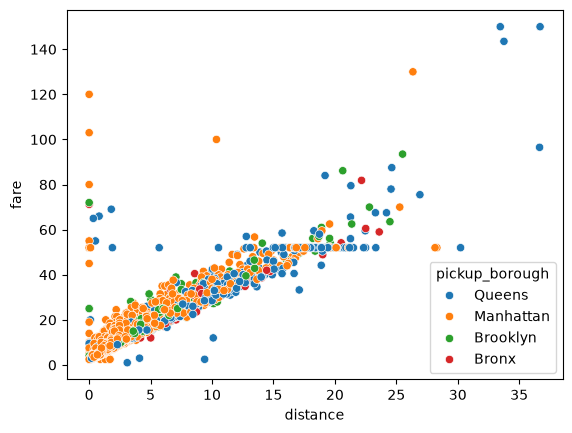

In [17]:
##  Scatter Plot

sns.scatterplot(
    x="distance",
    y="fare",
    hue="pickup_borough",
data=df
)
plt.show()


In [18]:
## Heat Map

correlation = df[["distance", "fare","tip","tolls","total"]].corr()
correlation

,distance,fare,tip,tolls,total
distance,1.000000,0.920108,0.452589,0.635267,0.904676
fare,0.920108,1.000000,0.488612,0.609307,0.974358
tip,0.452589,0.488612,1.000000,0.413619,0.646186
tolls,0.635267,0.609307,0.413619,1.000000,0.683142
total,0.904676,0.974358,0.646186,0.683142,1.000000


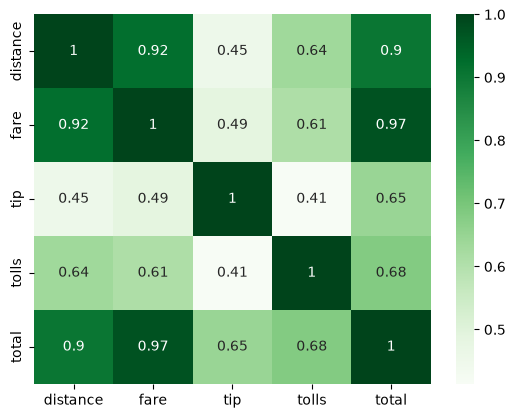

In [19]:
sns.heatmap(correlation, annot=True, cmap="Greens")
plt.show()

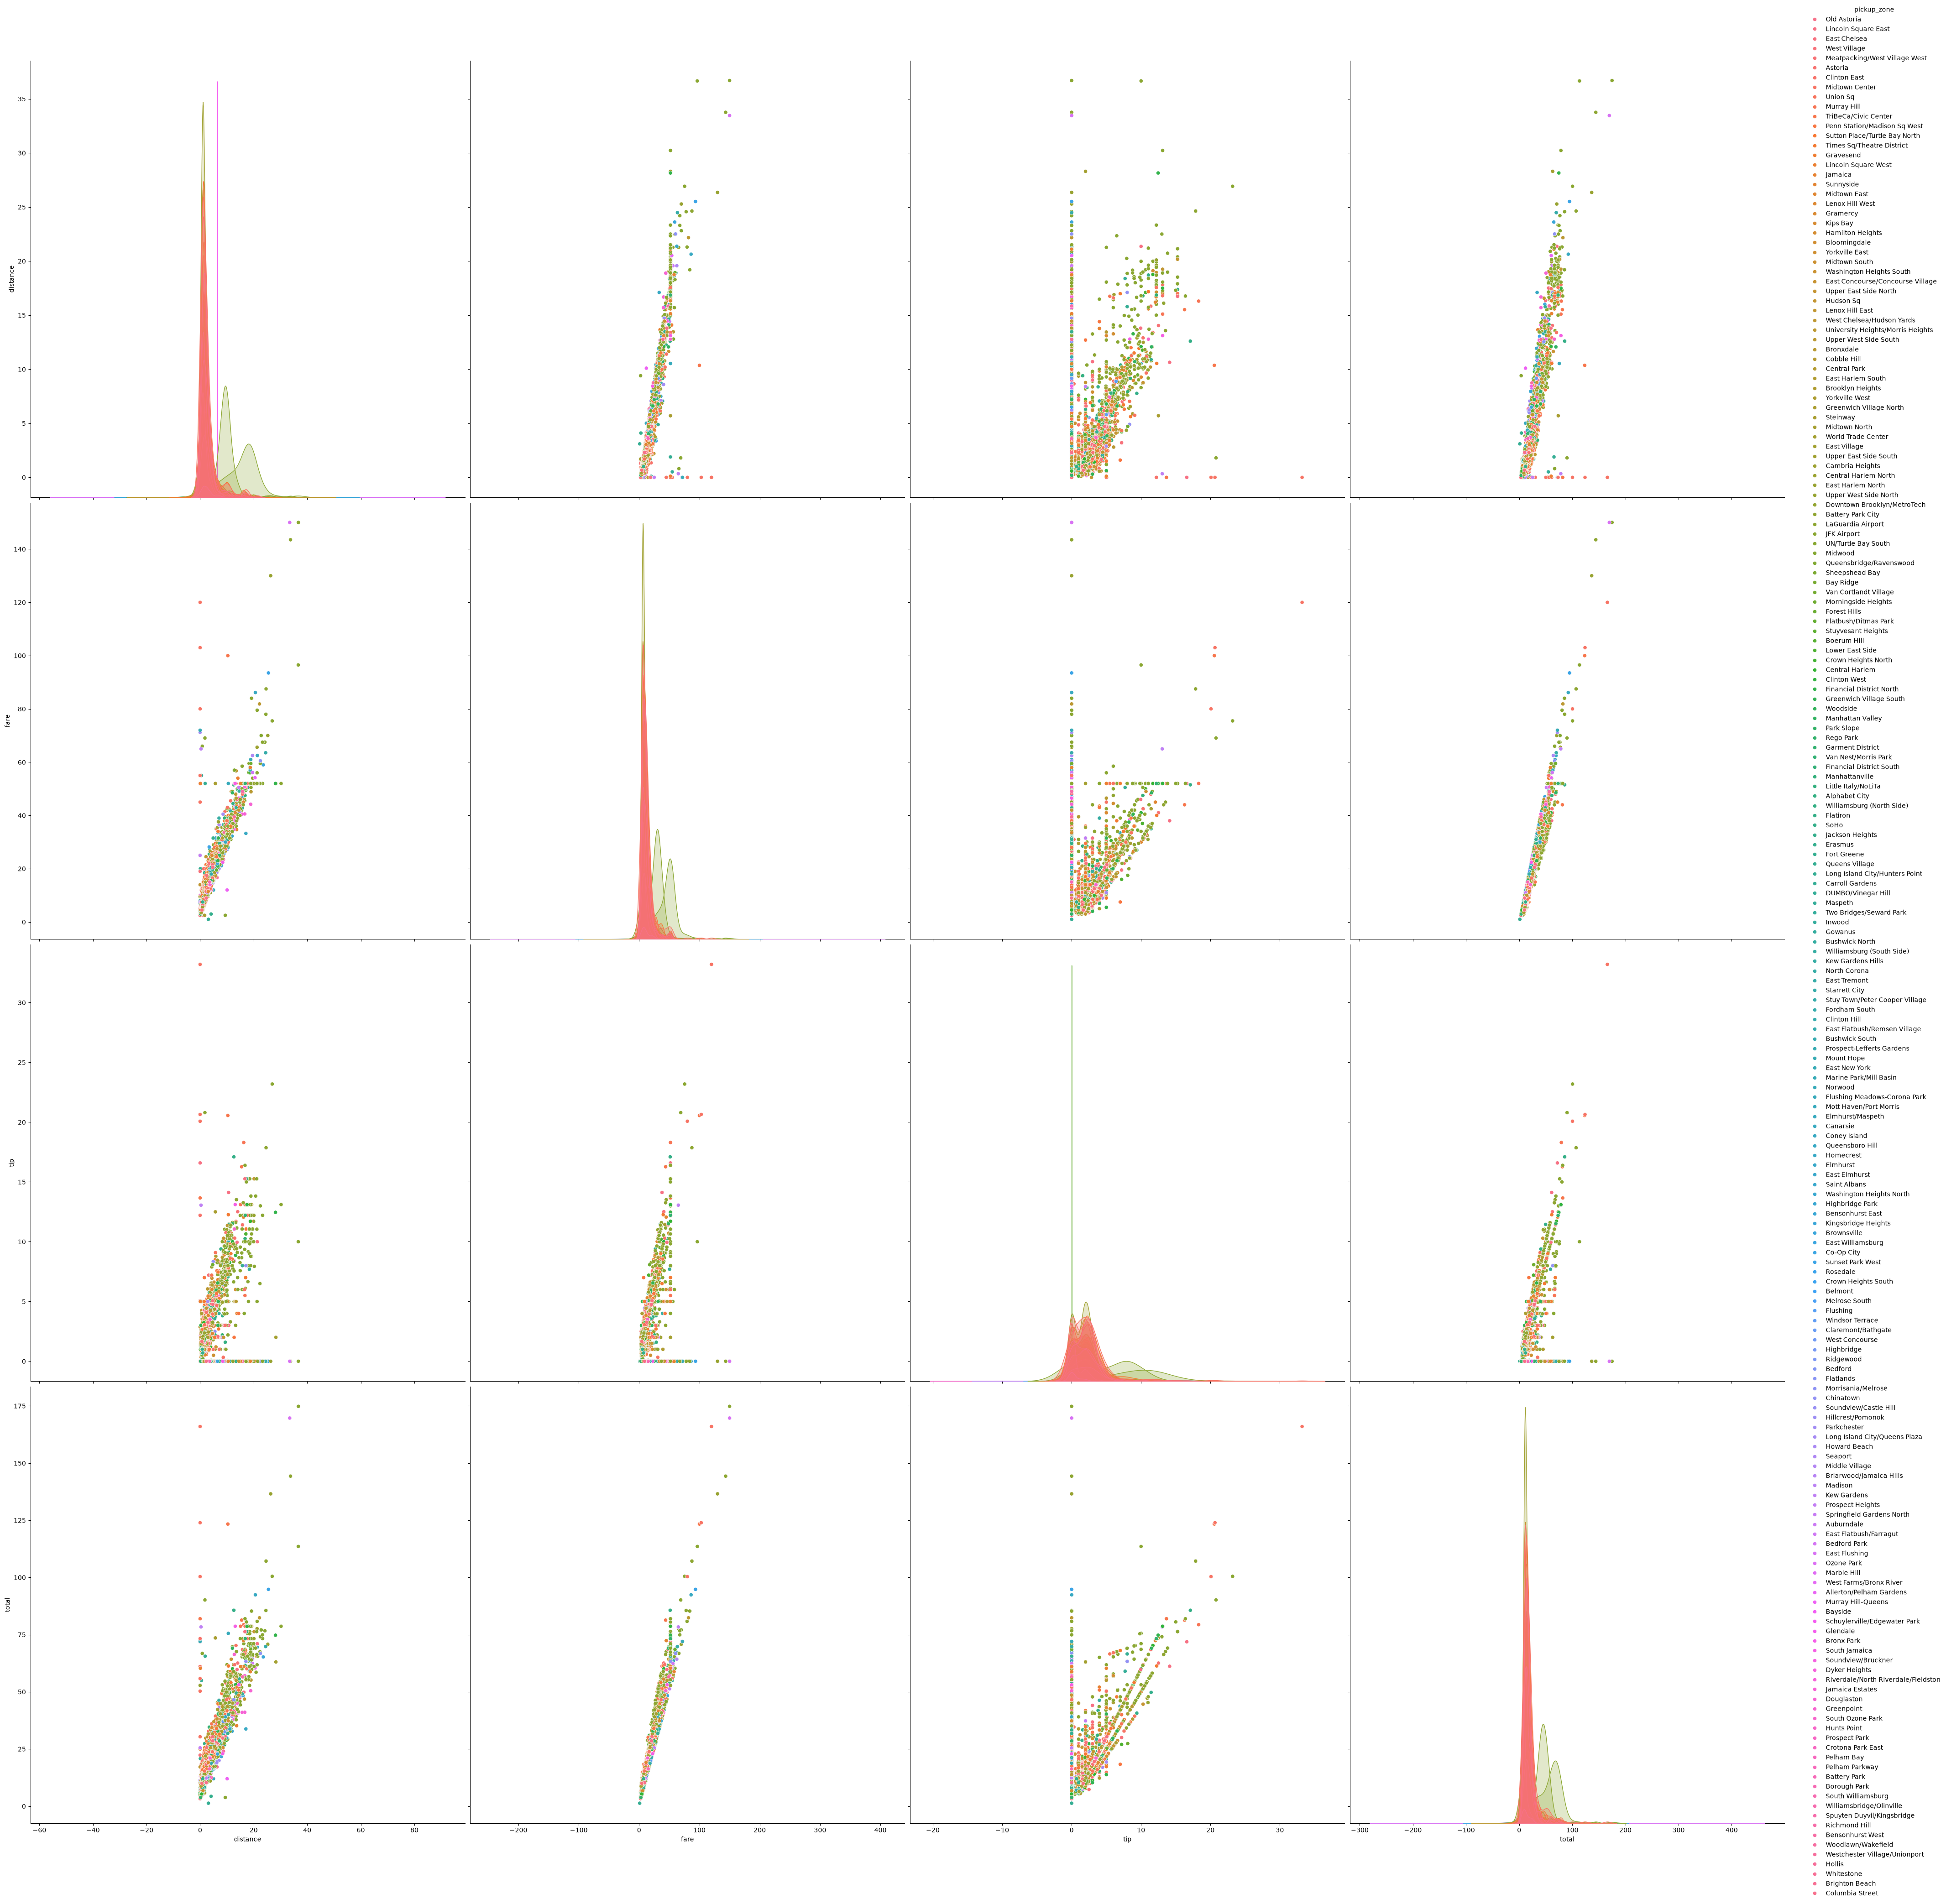

In [55]:
# 7. Pair Plot
sns.pairplot(df[["distance","fare","tip","total","pickup_zone"]],hue="pickup_zone",height=10)
plt.show()

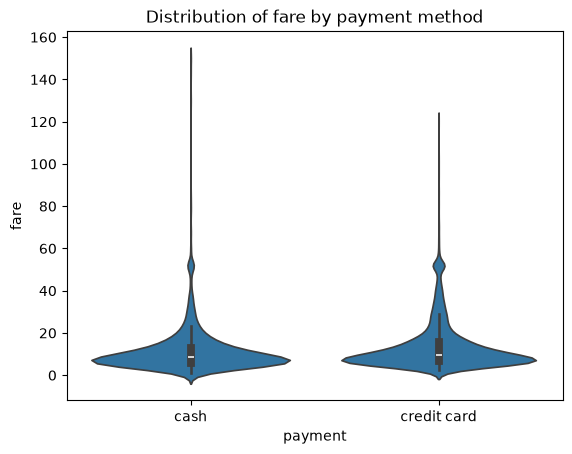

In [59]:
## Violin plot

sns.violinplot(x="payment", y="fare" ,data=df)
plt.title("Distribution of fare by payment method")
plt.show()